In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
df = pd.read_csv('ecommerce_clean_data.csv')

In [28]:
df.head()

,orderid,orderdate,customerid,paymentmethod,orderstatus,customername,gender,age,city,region,...,profit,productname,category,costprice,sellingprice,year,month,monthname,yearmonth,profitmarginpct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [29]:
df.shape

(12558, 27)

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   orderid          12558 non-null  str    
 1   orderdate        12558 non-null  str    
 2   customerid       12558 non-null  str    
 3   paymentmethod    12558 non-null  str    
 4   orderstatus      12558 non-null  str    
 5   customername     12558 non-null  str    
 6   gender           12558 non-null  str    
 7   age              12558 non-null  int64  
 8   city             12558 non-null  str    
 9   region           12558 non-null  str    
 10  signupdate       12558 non-null  str    
 11  orderdetailid    12558 non-null  str    
 12  productid        12558 non-null  str    
 13  quantity         12558 non-null  int64  
 14  unitprice        12558 non-null  float64
 15  discountpct      12558 non-null  float64
 16  salesamount      12558 non-null  float64
 17  profit           12558 

In [31]:
df.describe()

,age,quantity,unitprice,discountpct,salesamount,profit,costprice,sellingprice,year,month,profitmarginpct
count,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000
mean,39.065377,2.501752,6272.299570,10.742156,14010.138708,4804.382457,3680.883023,6272.299570,2024.835165,6.002150,31.293145
std,12.303175,1.119501,3461.536155,7.112802,10628.052040,4894.725391,1846.766235,3461.536155,0.762190,3.287781,13.355564
min,18.000000,1.000000,319.000000,0.000000,239.250000,-2048.000000,232.000000,319.000000,2024.000000,1.000000,-10.940224
25%,28.000000,2.000000,3416.000000,5.000000,5949.000000,1342.400000,2400.000000,3416.000000,2024.000000,3.000000,21.079173
50%,40.000000,2.000000,6288.000000,10.000000,11210.400000,3215.600000,3640.000000,6288.000000,2025.000000,6.000000,32.433378
75%,50.000000,4.000000,8847.000000,15.000000,20044.800000,6608.400000,5353.000000,8847.000000,2025.000000,9.000000,42.278551
max,60.000000,4.000000,14270.000000,25.000000,57080.000000,30860.000000,6882.000000,14270.000000,2026.000000,12.000000,54.342273


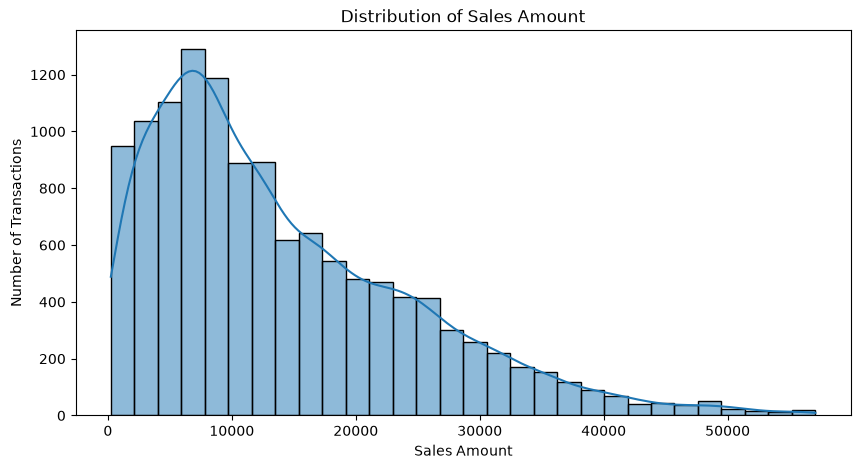

In [32]:
# 💰 Sales Distribution
plt.figure(figsize=(10,5))

sns.histplot(
    df['salesamount'],
    bins=30,
    kde=True
)

plt.title('Distribution of Sales Amount')
plt.xlabel('Sales Amount')
plt.ylabel('Number of Transactions')
plt.show()

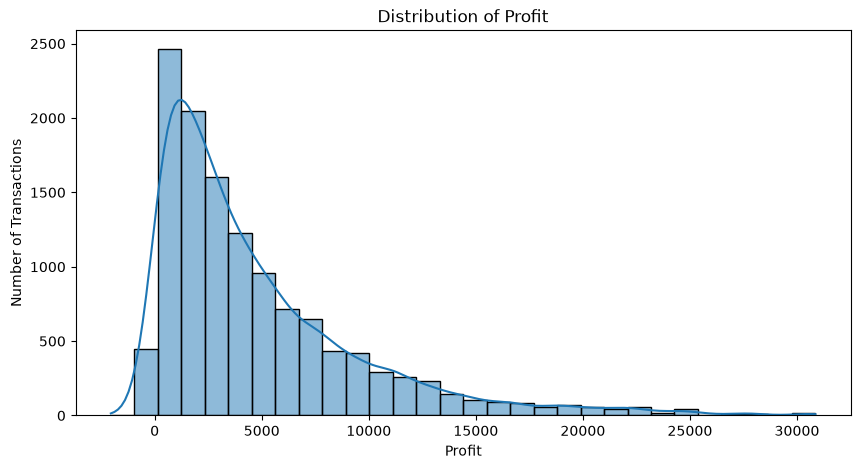

In [33]:
# Profit Distribution
plt.figure(figsize=(10,5))

sns.histplot(
    df["profit"],
    bins=30,
    kde=True
)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Number of Transactions")
plt.show()

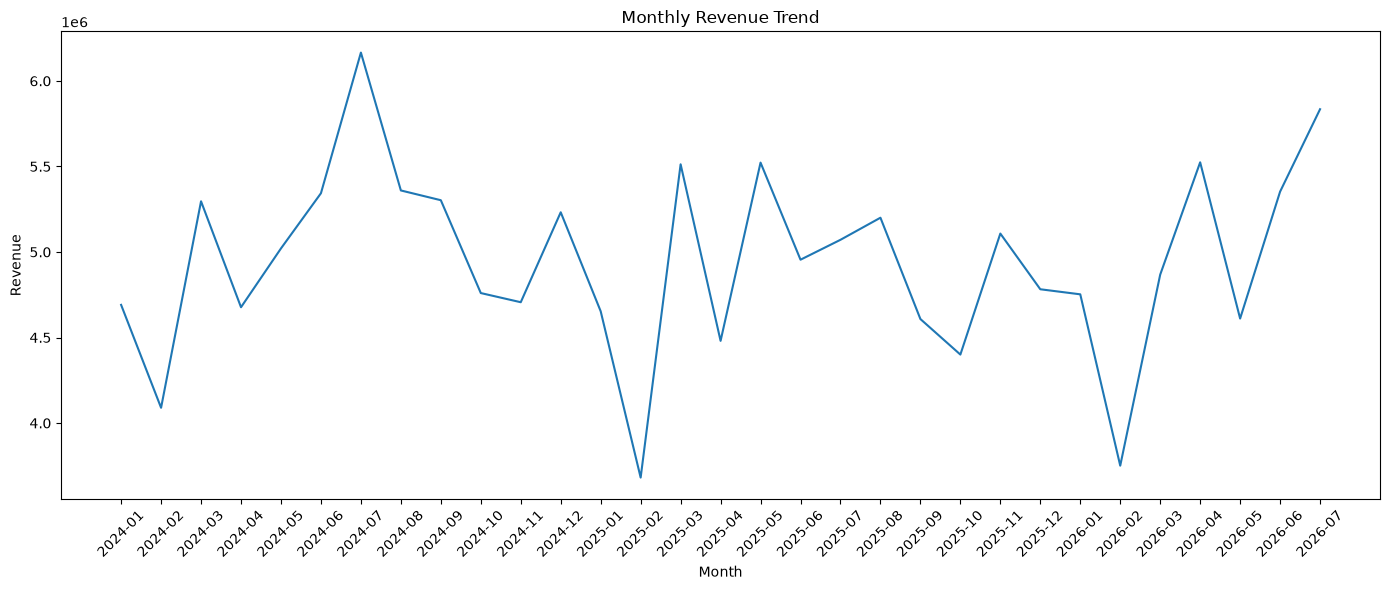

In [34]:
# 📅 Monthly Revenue Trend
monthly_sales = (
    df[df["orderstatus"] == "Delivered"]
    .groupby("yearmonth")["salesamount"]
    .sum()
    .reset_index()
)
monthly_sales
plt.figure(figsize=(14,6))

plt.plot(
    monthly_sales["yearmonth"],
    monthly_sales["salesamount"]
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

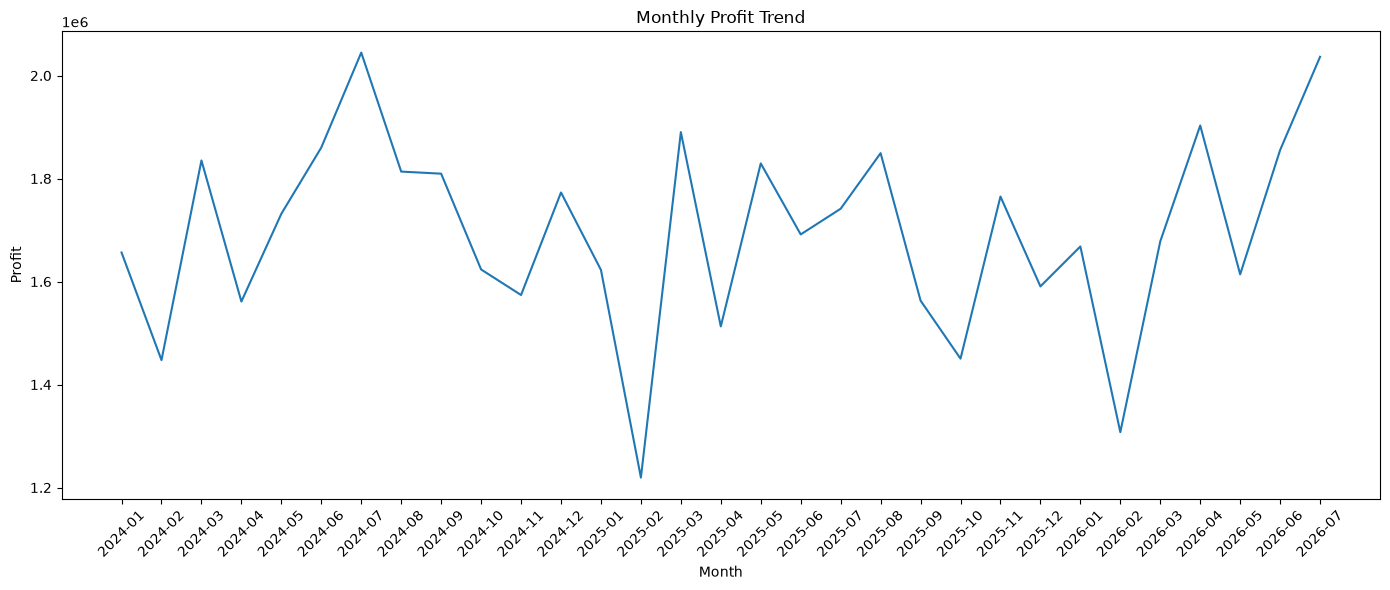

In [35]:
# Monthly Profit
monthly_profit = (
    df[df["orderstatus"] == "Delivered"]
    .groupby("yearmonth")["profit"]
    .sum()
    .reset_index()
)
monthly_profit
plt.figure(figsize=(14,6))

plt.plot(
    monthly_profit["yearmonth"],
    monthly_profit["profit"]
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

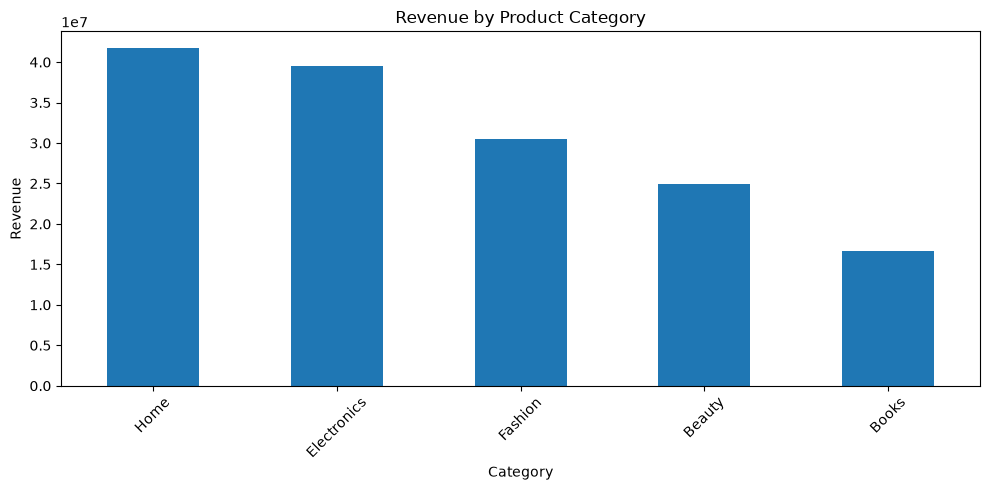

In [36]:
# 🛍️ Category Performance

category_sales = (
    df[df["orderstatus"] == "Delivered"]
    .groupby("category")["salesamount"]
    .sum()
    .sort_values(ascending=False)
)
category_sales
plt.figure(figsize=(10,5))

category_sales.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

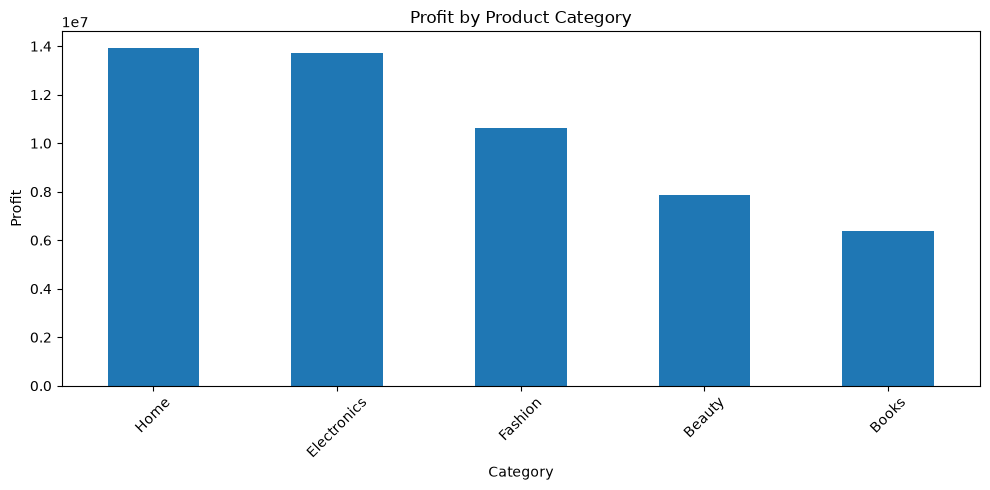

In [37]:
# Category Profit

category_profit = (
    df[df["orderstatus"] == "Delivered"]
    .groupby("category")["profit"]
    .sum()
    .sort_values(ascending=False)
)
plt.figure(figsize=(10,5))

category_profit.plot(kind="bar")

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

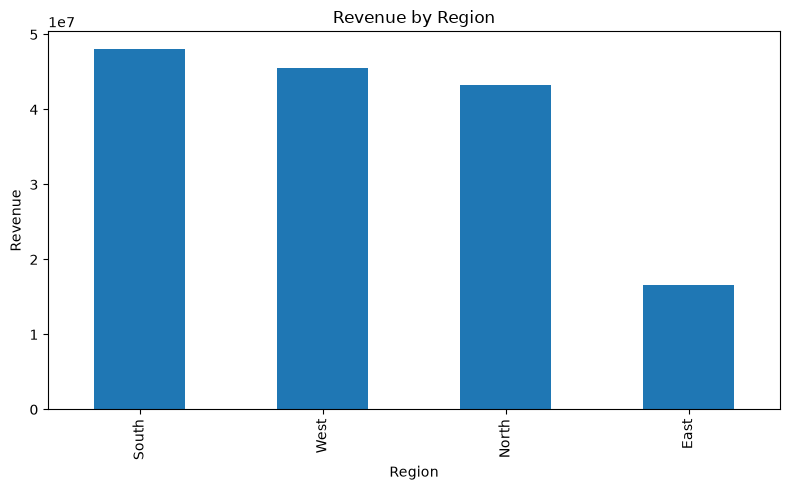

In [38]:
# 🌍 Region Performance

region_sales = (
    df[df["orderstatus"] == "Delivered"]
    .groupby("region")["salesamount"]
    .sum()
    .sort_values(ascending=False)
)
plt.figure(figsize=(8,5))

region_sales.plot(kind="bar")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

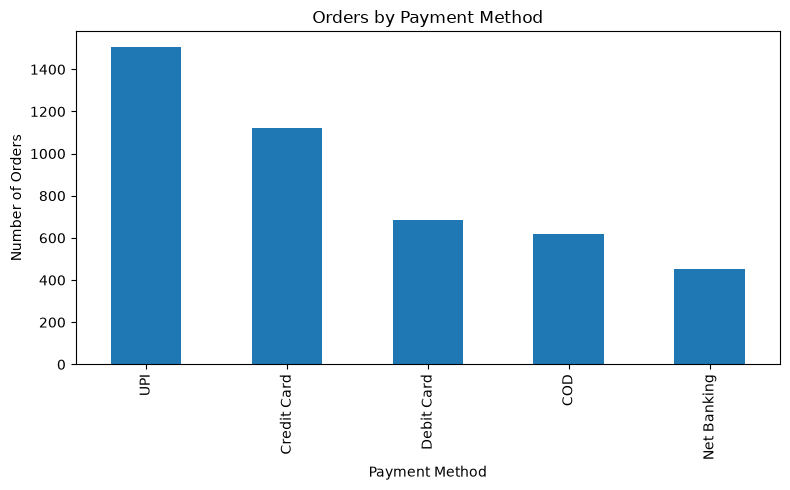

In [39]:
payment_analysis = (
    df[df["orderstatus"] == "Delivered"]
    .groupby("paymentmethod")["orderid"]
    .nunique()
    .sort_values(ascending=False)
)
payment_analysis
plt.figure(figsize=(8,5))

payment_analysis.plot(kind="bar")

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

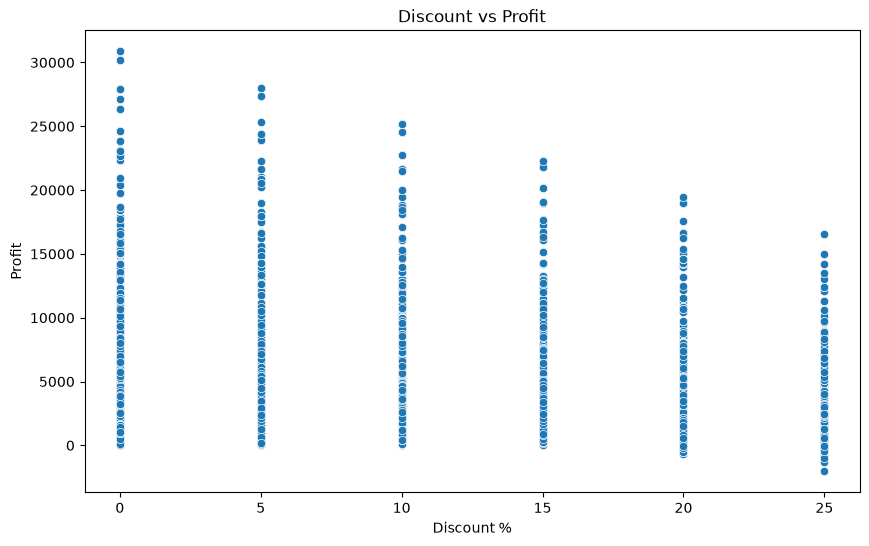

In [40]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df[df["orderstatus"] == "Delivered"],
    x="discountpct",
    y="profit"
)

plt.title("Discount vs Profit")
plt.xlabel("Discount %")
plt.ylabel("Profit")

plt.show()

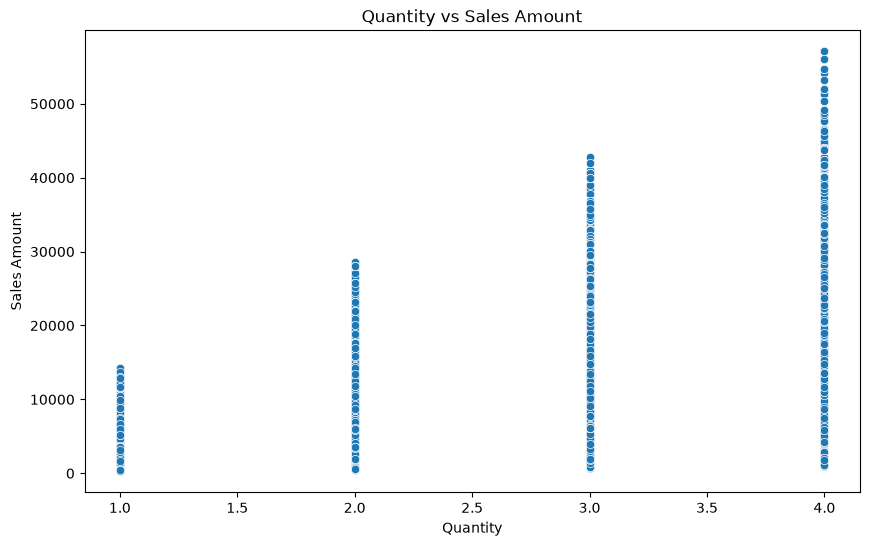

In [41]:
# Quantity vs Sales
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df[df["orderstatus"] == "Delivered"],
    x="quantity",
    y="salesamount"
)

plt.title("Quantity vs Sales Amount")
plt.xlabel("Quantity")
plt.ylabel("Sales Amount")

plt.show()

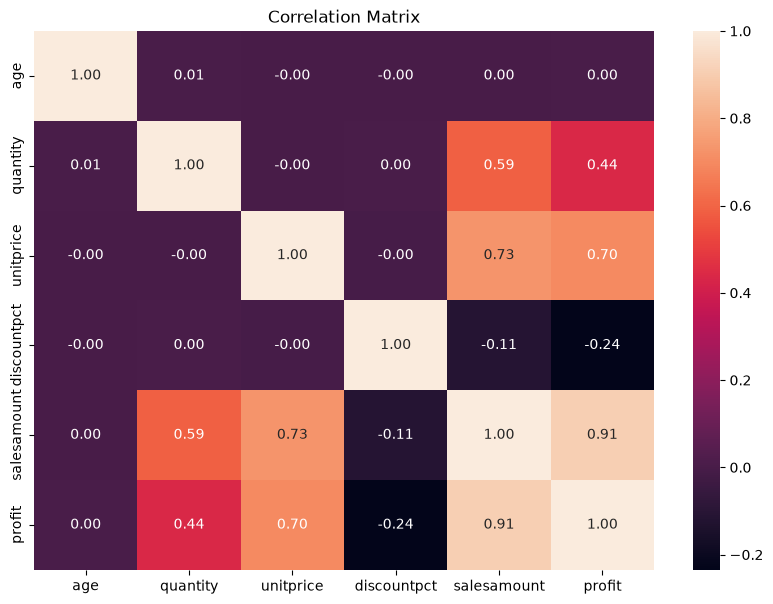

In [42]:
# Correlation
numeric_cols = [
    "age",
    "quantity",
    "unitprice",
    "discountpct",
    "salesamount",
    "profit"
]
correlation = df[numeric_cols].corr()
correlation
plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

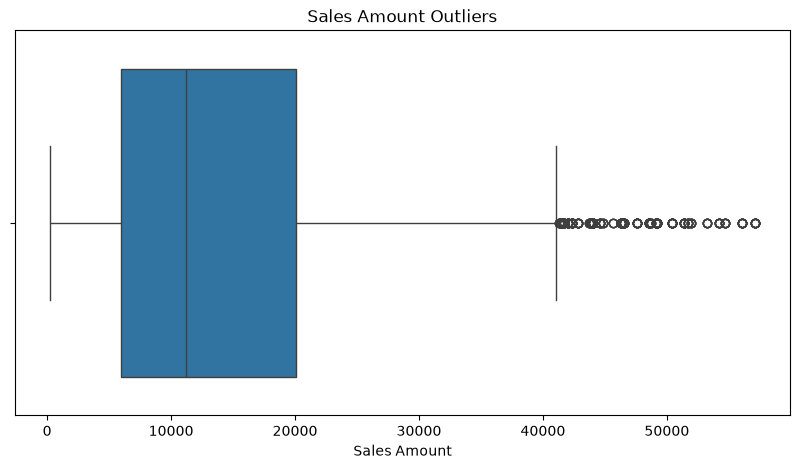

In [43]:
# Outlier Analysis
plt.figure(figsize=(10,5))

sns.boxplot(
    x=df["salesamount"]
)

plt.title("Sales Amount Outliers")
plt.xlabel("Sales Amount")

plt.show()


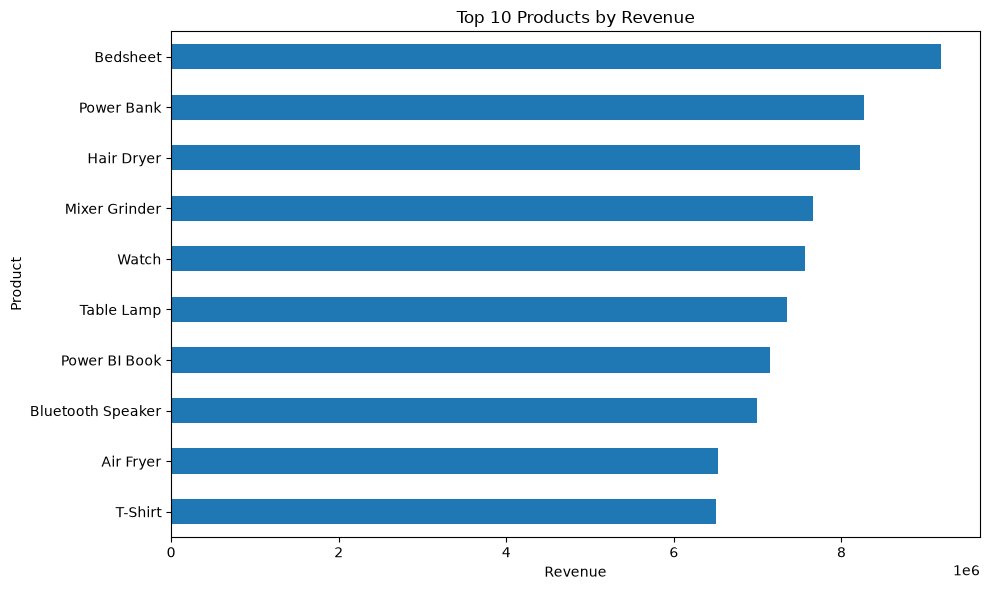

In [44]:
top_products = (
    df[df["orderstatus"] == "Delivered"]
    .groupby("productname")["salesamount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
plt.figure(figsize=(10,6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [45]:
# Return Reason Analysis
import pandas as pd
import psycopg2

In [46]:
try:
    conn = psycopg2.connect(
        host="aws-1-ap-northeast-1.pooler.supabase.com",
        database="postgres",
        user="postgres.nwiclgclxgfvoydnpevr",
        password="D@t@Dh@r@n007",
        port=5432,
        sslmode="require"
    )

    print("Connected successfully!")

except psycopg2.OperationalError as e:
    print("Database connection failed!")
    print("Error:", e)

except Exception as e:
    print("Something went wrong!")
    print("Error:", e)

Connected successfully!


In [47]:
returns = pd.read_sql(
    "SELECT * FROM Returns",
    conn
)

C:\Users\dhara\AppData\Local\Temp\ipykernel_24864\1230352464.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  returns = pd.read_sql(


In [48]:
returns.head()

,returnid,orderid,returndate,returnreason
0,R00001,O00016,1970-01-01,Damaged
1,R00002,O00078,1970-01-01,Wrong Product
2,R00003,O00088,1970-01-01,Size Issue
3,R00004,O00124,1970-01-01,Size Issue
4,R00005,O00125,1970-01-01,Late Delivery


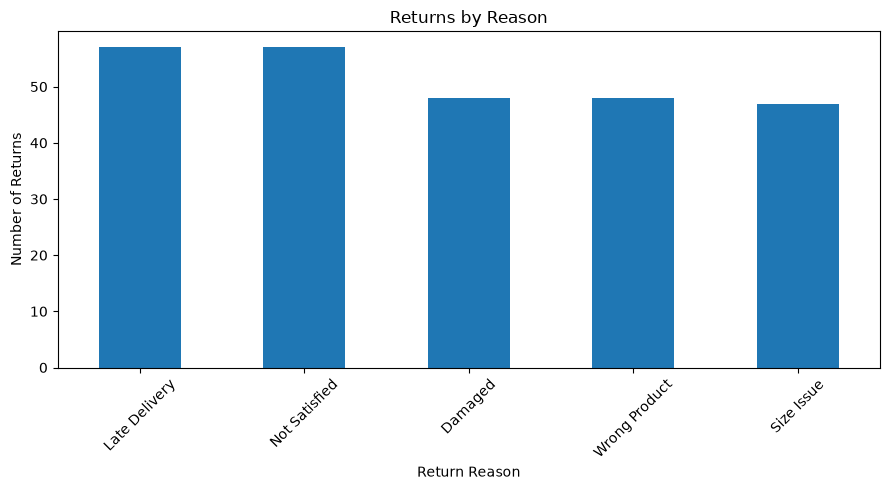

In [49]:
return_analysis = (
    returns
    .groupby("returnreason")
    .size()
    .sort_values(ascending=False)
)
plt.figure(figsize=(9,5))
return_analysis.plot(kind="bar")

plt.title("Returns by Reason")
plt.xlabel("Return Reason")
plt.ylabel("Number of Returns")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
eda_summary = pd.DataFrame({
    "Analysis": [
        "Monthly Revenue",
        "Category Performance",
        "Region Performance",
        "Discount vs Profit",
        "Top Products",
        "Return Reasons"
    ],
    "Business_Purpose": [
        "Identify sales trend",
        "Find high-performing categories",
        "Compare regional performance",
        "Understand discount impact",
        "Identify important products",
        "Identify return problems"
    ]
})

eda_summary

,Analysis,Business_Purpose
0,Monthly Revenue,Identify sales trend
1,Category Performance,Find high-performing categories
2,Region Performance,Compare regional performance
3,Discount vs Profit,Understand discount impact
4,Top Products,Identify important products
5,Return Reasons,Identify return problems
